In [ ]:
import numpy as np
import pandas as pd
from numpy import loadtxt
import matplotlib.pyplot as plt

Smarket data is loaded here and values are placed in training sets and testing sets respectinely.

In [ ]:
data_frame = pd.read_csv(r"/content/smarket (1).csv")

# Creating the design matrix X and target vector y
X = data_frame[['Lag1', 'Lag2', 'Lag3', 'Lag4', 'Lag5', 'Volume', 'Today']].values
X = np.column_stack((np.ones(len(X)), X))  # Adding bias term to the feature matrix
y = (data_frame['Direction'] == 'Up').astype(int).values # If the argument is true a value of 1 is assigned else 0

# Spliting data into training and test sets
X_train = X[data_frame['Year'] < 2005]
y_train = y[data_frame['Year'] < 2005]
X_test = X[data_frame['Year'] == 2005]
y_test = y[data_frame['Year'] == 2005]

Correlation matrix is calculated here by leaving the first column.
The variables that show significant correlation are 'Volume' and 'Lag1' , also 'Lag 5' and 'Today' also show relatively stronger correlation as compared to the other variables in the dataset.

In [ ]:
data = data_frame.iloc[:, 1:]

# Computing the correlation matrix using .corr() function
correlation = data.corr()

print("Correlation Matrix")
print(correlation)

Correlation Matrix
            Lag1      Lag2      Lag3      Lag4      Lag5    Volume     Today
Lag1    1.000000 -0.026294 -0.010803 -0.002986 -0.005675  0.040910 -0.026155
Lag2   -0.026294  1.000000 -0.025897 -0.010854 -0.003558 -0.043383 -0.010250
Lag3   -0.010803 -0.025897  1.000000 -0.024051 -0.018808 -0.041824 -0.002448
Lag4   -0.002986 -0.010854 -0.024051  1.000000 -0.027084 -0.048414 -0.006900
Lag5   -0.005675 -0.003558 -0.018808 -0.027084  1.000000 -0.022002 -0.034860
Volume  0.040910 -0.043383 -0.041824 -0.048414 -0.022002  1.000000  0.014592
Today  -0.026155 -0.010250 -0.002448 -0.006900 -0.034860  0.014592  1.000000


<ipython-input-224-4a91153b70c6>:4: FutureWarning: The default value of numeric_only in DataFrame.corr is deprecated. In a future version, it will default to False. Select only valid columns or specify the value of numeric_only to silence this warning.
  correlation = data.corr()


Defining the sigmoid function

In [ ]:
def sigmoid(z): #can we write a numerically stable routine for this?
    return 1 / (1 + np.exp(-z))

Defining gradient function



In [ ]:
def fullGradient(w, X, y):
    N, d = X.shape
    grad = np.zeros(d)
    for i in range(N):
        grad += (sigmoid(np.dot(X[i], w)) - y[i]) * X[i]
    return grad

 Defining  stochastic gradient function

In [ ]:
def randGradient(w, X, y, n):
    grad = (sigmoid(np.dot(X[n], w)) - y[n]) * X[n]
    return grad

Defining a subroutine for the learning rate

In [ ]:
def rho(t):
   return 1/np.sqrt(t)

Defining fdescent function that would return the w-vector and the history of the functional, a vector f such that f[t] contains the value of the objective function in the t-th iteration.

In [ ]:
def fdescent(X, y, rho, job, nEpoch):
    permuted_indices = []
    grad = []
    N, d = X.shape
    w = np.zeros(d)  # Initialize parameters to zero
    f_history = []   # To store the history of objective function values

    for epoch in range(nEpoch):
        if job == 'full':
            permuted_indices = np.arange(N)  # No permutation needed for full gradient
        elif job == 'stochastic':
            permuted_indices = np.random.permutation(N)  # Permuted indices for stochastic gradient

        for i in permuted_indices:
            if job == 'full':
                grad = fullGradient(w, X, y)
            elif job == 'stochastic':
                grad = randGradient(w, X, y, i)

            w -= rho(epoch * N + i + 1) * grad  # Updation of weights in each iteration

            # Computing objective function value and storing in history
            epsilon = 1e-8# This is to make the calculation of objective funtion numerically stable when the argument of logarithm function is close to zero
            f = -np.mean(y * np.log(np.maximum(sigmoid(np.dot(X, w)), epsilon)) + (1 - y) * np.log(np.maximum(1 - sigmoid(np.dot(X, w)), epsilon)))
            f_history.append(f)

    return w, f_history

Plots of Gradient descent (GD) and Stochastic Gradient Descent (SGD) are being plotted here. The graph of GD tends to show smoother convergence behavior with a more predictable trajectory path, while the graph of SGD may exhibit more fluctuations and irregularities in convergence due to its stochastic updates.
SGD requires fewer floating point operations than GD.

<ipython-input-212-c893dc62d4b9>:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


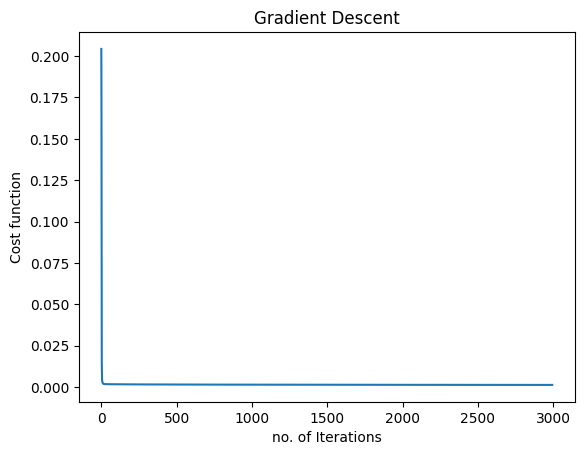

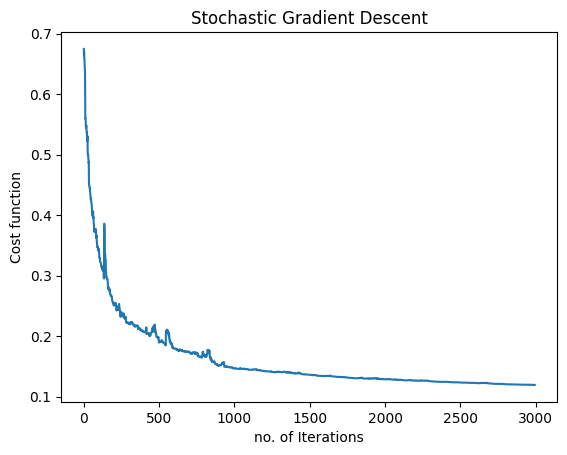

In [ ]:
w1, f1 = fdescent(X_train, y_train, rho, 'full', nEpoch=3)
w2, f2 = fdescent(X_train, y_train, rho, 'stochastic', nEpoch=3)

# Plotting the history of objective function values
plt.plot(f1, label='Gradient Descent')
plt.xlabel('no. of Iterations')
plt.ylabel('Cost function')
plt.title('Gradient Descent')
plt.show()
plt.plot(f2, label='Stochastic Gradient Descent')
plt.xlabel('no. of Iterations')
plt.ylabel('Cost function')
plt.title('Stochastic Gradient Descent')
plt.show()

Defining the routine predictions that would predict the values for the testing set.

In [ ]:
def predictions(X, y, w):
    y_pred = (sigmoid(np.dot(X, w)) >= 0.5).astype(int) #if the argument is true, 1 is assigned else 0
    misclassified = np.sum(y_pred != y)
    return y_pred, misclassified

After calculating the predictions of the testing data, predicted values were compared with the actual data of direction and no. of missclassified points are displayed here.
First, using the weight vector calculated by Gradient Descent method, predictions are being calculated.

In [ ]:
y_pred1, misclassified1= predictions(X_test, y_test, w1)
print("Misclassified points using Full Gradient Descent method):", misclassified1)

Misclassified points using Full Gradient Descent method): 0


<ipython-input-212-c893dc62d4b9>:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


Then, using the weight vector calculated by Stochastic Gradient Descent, predictions are being calculated.
Since the no. of missclassified points for Gradient Descent method were less as compared to Stochastic Descent mthod, therefore for this dataset the Gradient descent method is better than the Stochastic Gradient Descent method.

In [ ]:
y_pred2, misclassified2= predictions(X_test, y_test, w2)
print("Misclassified points (Stochastic Gradient Descent):", misclassified2)

Misclassified points (Stochastic Gradient Descent): 3


Modifying the data

In [ ]:
X_modified = X[:-1]
y_modified = y[1:]
i = data_frame['Year'][:-1] < 2005
X_trainm = X_modified[i]
y_trainm = y_modified[i]
X_testm = X_modified[data_frame['Year'][:-1] == 2005]
y_testm = y_modified[data_frame['Year'][:-1] == 2005]

On modifying the dataset and operating it with the two methods, it can be seen that this modification is inconsequential as we get more no. of missclassified points for this dataset as compared to the original one

In [ ]:
w1m, _ = fdescent(X_trainm, y_trainm, rho, 'full', nEpoch=3)
w2m, _ = fdescent(X_trainm, y_trainm, rho, 'stochastic', nEpoch=3)

# Predictions and misclassifications for full gradient descent (modified data)
y_pred_full_modified, misclassified_full_modified = predictions(X_testm, y_testm, w1)
print("Misclassified points using Full Gradient Descent method on modified data):", misclassified_full_modified)

# Predictions and misclassifications for stochastic gradient descent (modified data)
y_pred_stochastic_modified, misclassified_stochastic_modified = predictions(X_testm, y_testm, w2m)
print("Misclassified points using Stochastic Gradient Descent on modified data):", misclassified_stochastic_modified)

<ipython-input-212-c893dc62d4b9>:2: RuntimeWarning: overflow encountered in exp
  return 1 / (1 + np.exp(-z))


Misclassified points using Full Gradient Descent method on modified data): 140
Misclassified points using Stochastic Gradient Descent on modified data): 130
